# Outside wind versus top-ring sonic anemometers (v1)

**Author:** Aaron Roodman (with Claude)  
**Date Created:** 2026-11-04  
**Last Modified:** 2026-11-04  
**Status:** In Progress  
**Keywords:** wind, sonic anemometer, ESS airTurbulence, dome, TMA top ring, into-the-wind  

## Description
Compares the outside wind with the airflow measured by the four three-axis sonic anemometers
on the Telescope Mount Assembly (TMA) top ring (Environmental Sensor Suite (ESS) salIndex
123 to 126), per exposure.

- Outside wind: `wind_speed_ms` [m/s] and `wind_dir_deg` [deg, direction the wind comes from],
  from ConsDB.
- Pointing: `into_wind_deg` = wind_dir − azimuth wrapped to ±180 deg; 0 means the telescope
  points into the wind. The dome is assumed to track the TMA, so this is also the slit
  direction relative to the wind.
- Altitude [deg] from ConsDB `cdb_lsstcam.exposure`.
- Sonic: per-axis mean over the exposure [m/s]. **Axis 2 is the TMA optical axis**; the
  directions of axes 0 and 1 are not yet known (Karla is checking). Sign convention of axis
  2 (toward or away from M1) is also not yet confirmed.

On-sky exposures only (`img_type` science, acq, cwfs), 20260120 onward, where the sonic
data start.

**Output:** one PDF, `wind_vs_sonic.pdf`, in the study run directory.  
**References:** `value_added/docs/schema.md` (`sonic`, `wind_derived` groups).


## Change Log

| Date | Author | Description |
|------|--------|-------------|
| 2026-11-04 | Aaron Roodman | Initial version |

## Table of Contents

1. [Parameters](#params)
2. [Setup & Imports](#setup)
3. [Helper Functions](#functions)
4. [Data Access](#data)
5. [Analysis](#analysis)
6. [Results & Plots](#results)

<a id='params'></a>
## Parameters

In [1]:
from rubinwork.common import study_run

DAY_OBS_MIN = 20260120            # first night with sonic data
IMG_TYPES = ('science', 'acq', 'cwfs')
SONICS = (123, 124, 125, 126)     # TMA top ring
WIND_BINS = [0, 3, 6, 9, 30]      # outside wind speed bins [m/s]
ANGLE_STEP = 15                   # into_wind_deg bin width [deg]
ALT_BINS = [15, 45, 60, 70, 90]   # altitude bins [deg]
WIND_MIN_ALT = 6.0                # outside wind cut for the altitude page [m/s]

run = study_run('airflow/airflow_correlations', 'wind_vs_sonic')
PDF = run.path / 'wind_vs_sonic.pdf'

<a id='setup'></a>
## Setup & Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import statsmodels.api as sm
from scipy import stats

from rubinwork.products.value_added import reader
from rubinwork.common.telemetry_clients import make_consdb_client
from rubinwork.common.utils import nmad

<a id='functions'></a>
## Helper Functions

In [3]:
def binned_median(x, y, edges):
    """Median and count of y in bins of x."""
    idx = np.digitize(x, edges) - 1
    cen = 0.5 * (edges[1:] + edges[:-1])
    med = np.full(cen.size, np.nan)
    n = np.zeros(cen.size, int)
    for k in range(cen.size):
        sel = (idx == k) & np.isfinite(y)
        n[k] = sel.sum()
        if n[k] >= 20:
            med[k] = np.median(y[sel])
    return cen, med, n


def huber_fit(x, y):
    """Huber robust line y = a + b x; returns a, b, their errors and nmad of residuals."""
    ok = np.isfinite(x) & np.isfinite(y)
    res = sm.RLM(y[ok], sm.add_constant(x[ok]), M=sm.robust.norms.HuberT()).fit()
    return res.params, res.bse, nmad(res.resid), ok.sum()

<a id='data'></a>
## Data Access

In [4]:
con = reader.open_db()
cols = ['visit_id', 'day_obs', 'seq_num', 'wind_speed_ms', 'wind_dir_deg', 'azimuth_deg',
        'into_wind_deg']
for i in SONICS:
    cols += [f'sonic{i}_mean_{a}_ms' for a in range(3)] + [f'sonic{i}_rms_2_ms']
vt = con.sql(f"select {', '.join(cols)} from visit_telemetry "
             f"where day_obs >= {DAY_OBS_MIN}").df()

cdb = make_consdb_client()
ex = cdb.query(f"select exposure_id as visit_id, img_type, altitude from cdb_lsstcam.exposure "
               f"where day_obs >= {DAY_OBS_MIN}").to_pandas()
d = vt.merge(ex, on='visit_id', how='inner')
d['altitude'] = pd.to_numeric(d['altitude'], errors='coerce')
d = d[d.img_type.isin(IMG_TYPES) & d.altitude.notna() & d.wind_speed_ms.notna()
      & d.into_wind_deg.notna()].copy()
d['u_par'] = d.wind_speed_ms * np.cos(np.radians(d.into_wind_deg))
print(f'{len(d)} on-sky exposures, {d.day_obs.nunique()} nights, '
      f'{d.day_obs.min()} to {d.day_obs.max()}')
for i in SONICS:
    print(f'sonic{i}: {d[f"sonic{i}_mean_2_ms"].notna().sum()} exposures with axis 2')

        Use pytest instead. [astropy.tests.runner]
        Use pytest instead.


        Use pytest instead. [astropy.utils.decorators]
        Use pytest instead.


70454 on-sky exposures, 111 nights, 20260127 to 20260714
sonic123: 69284 exposures with axis 2
sonic124: 69282 exposures with axis 2
sonic125: 69741 exposures with axis 2
sonic126: 69743 exposures with axis 2


<a id='analysis'></a>
## Analysis

Correlation of the axis-2 mean [m/s] with the outside wind component along the pointing, `u_par` = wind_speed × cos(into_wind_deg) [m/s], and Huber fits.

In [5]:
rows = []
for i in SONICS:
    y = d[f'sonic{i}_mean_2_ms'].to_numpy()
    x = d.u_par.to_numpy()
    ok = np.isfinite(x) & np.isfinite(y)
    (a, b), (ea, eb), sc, n = huber_fit(x, y)
    rows.append(dict(sonic=i, n=n,
                     pearson_r=stats.pearsonr(x[ok], y[ok])[0],
                     spearman_rho=stats.spearmanr(x[ok], y[ok])[0],
                     intercept_ms=a, slope=b, slope_err=eb, resid_nmad_ms=sc,
                     median_ax2_ms=np.median(y[ok])))
summary = pd.DataFrame(rows).set_index('sonic')
print('axis-2 mean [m/s] vs u_par [m/s]; slope dimensionless (axis-2 m/s per outside m/s)')
summary.round(3)

axis-2 mean [m/s] vs u_par [m/s]; slope dimensionless (axis-2 m/s per outside m/s)


,n,pearson_r,spearman_rho,intercept_ms,slope,slope_err,resid_nmad_ms,median_ax2_ms
sonic,,,,,,,,
123,69284,0.224,0.288,0.291,0.029,0.0,0.351,0.260
124,69282,-0.154,-0.131,0.081,-0.008,0.0,0.327,0.046
125,69741,-0.545,-0.518,-0.017,-0.062,0.0,0.324,-0.033
126,69743,-0.077,0.068,0.168,0.006,0.0,0.296,0.121


<a id='results'></a>
## Results & Plots

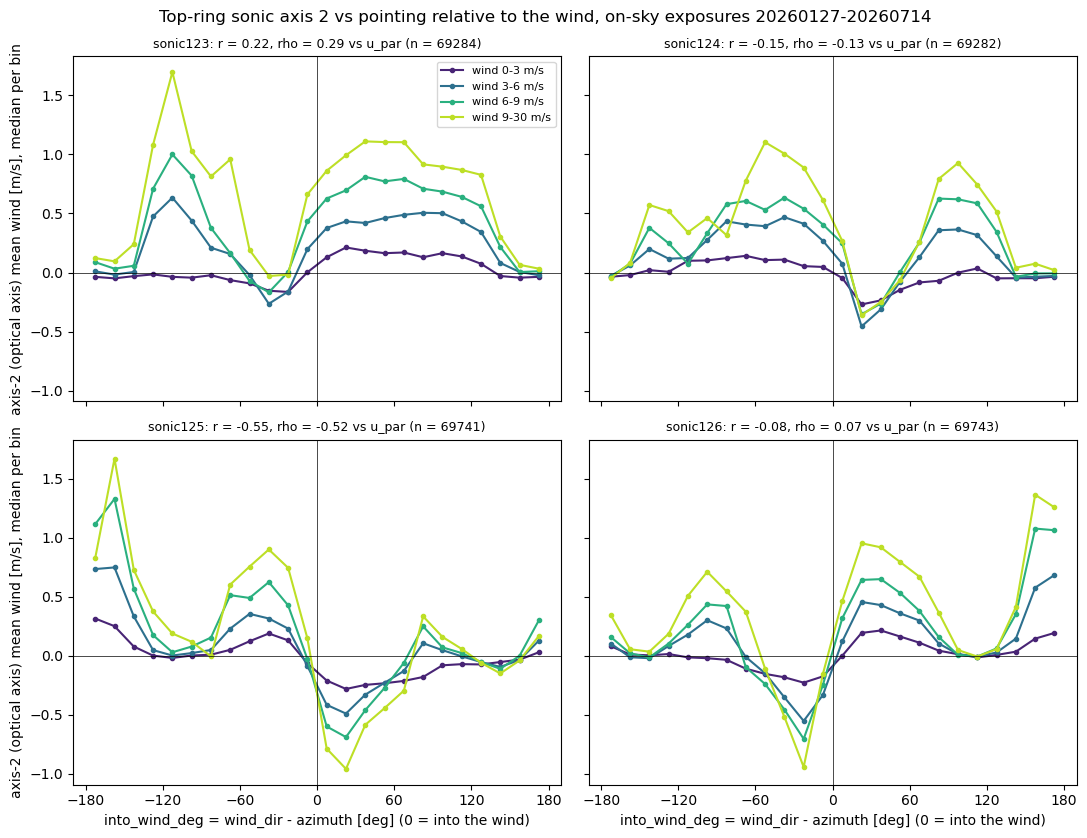

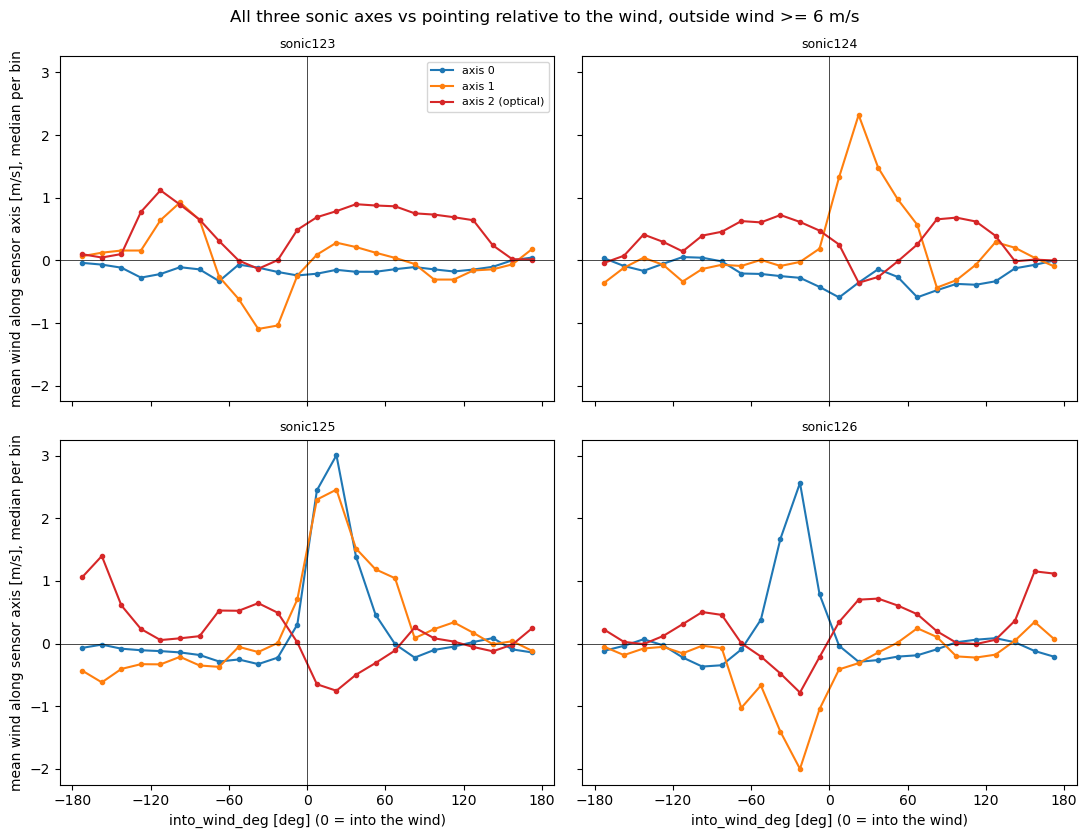

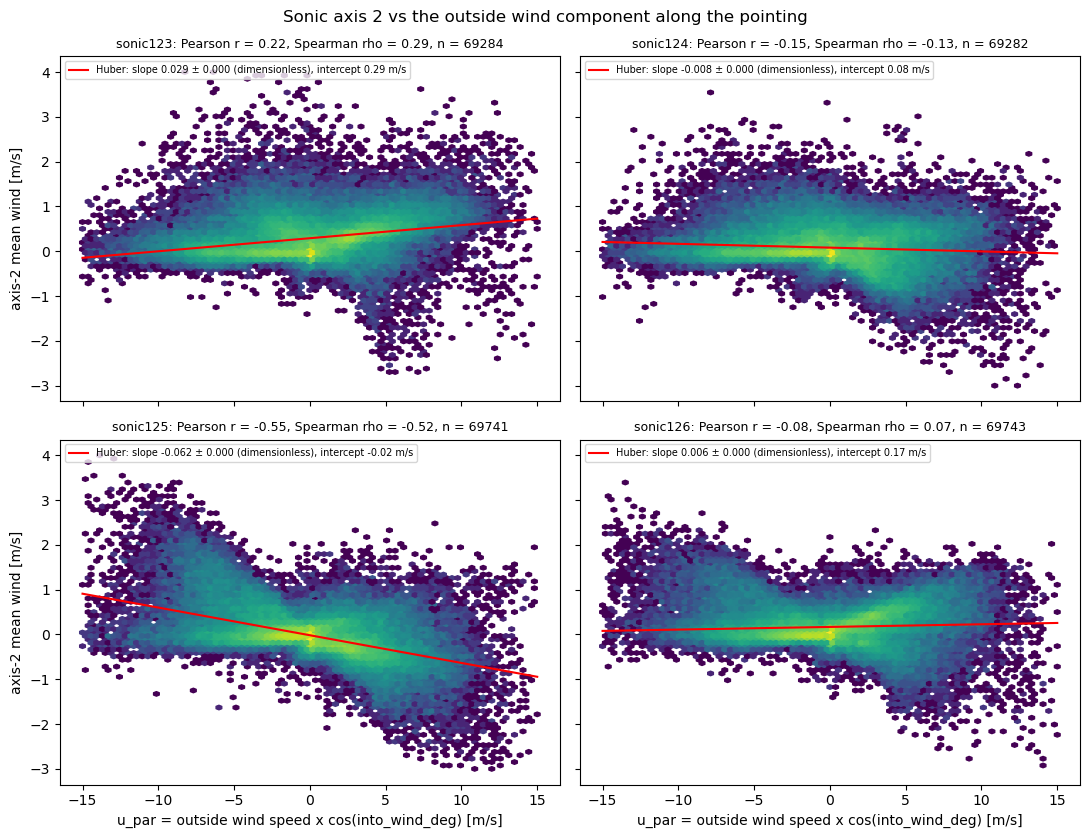

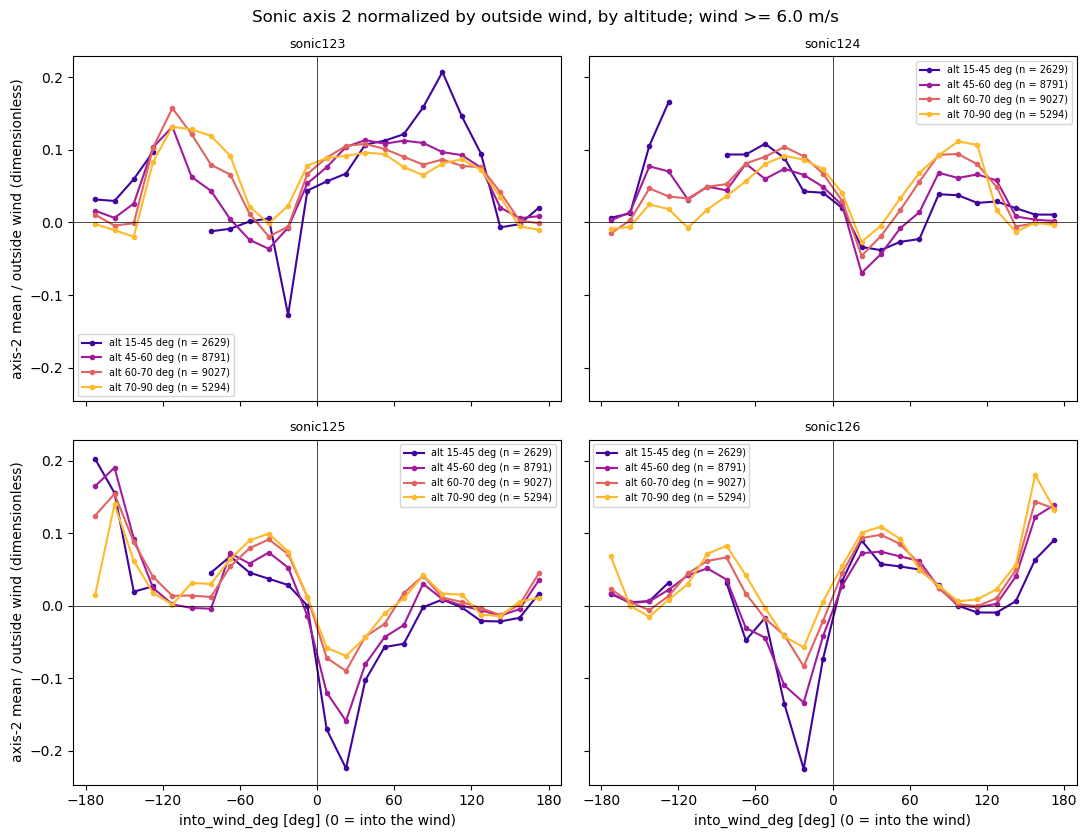

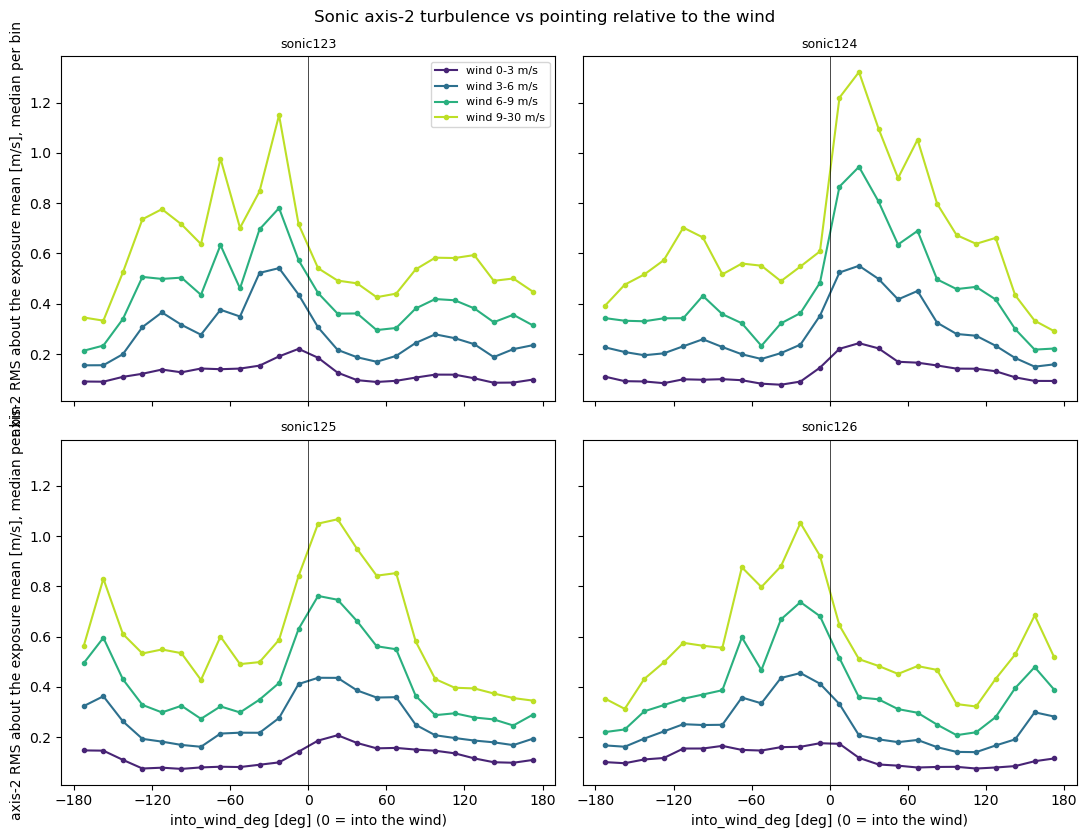

/sdf/group/rubin/u/roodman/LSST/rubin-work/studies/airflow/airflow_correlations/20261104_wind_vs_sonic/wind_vs_sonic.pdf


In [6]:
edges = np.arange(-180, 181, ANGLE_STEP)
wcol = plt.cm.viridis(np.linspace(0.1, 0.9, len(WIND_BINS) - 1))
pdf = PdfPages(PDF)

# Page 1: summary, axis-2 median vs into_wind_deg by wind bin
fig, axs = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True, sharey=True)
for ax, i in zip(axs.flat, SONICS):
    for k in range(len(WIND_BINS) - 1):
        sel = (d.wind_speed_ms >= WIND_BINS[k]) & (d.wind_speed_ms < WIND_BINS[k + 1])
        c, m, n = binned_median(d.into_wind_deg[sel].to_numpy(),
                                d[f'sonic{i}_mean_2_ms'][sel].to_numpy(), edges)
        ax.plot(c, m, 'o-', ms=3, color=wcol[k],
                label=f'wind {WIND_BINS[k]}-{WIND_BINS[k+1]} m/s')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    s = summary.loc[i]
    ax.set_title(f'sonic{i}: r = {s.pearson_r:.2f}, rho = {s.spearman_rho:.2f} vs u_par '
                 f'(n = {s.n:.0f})', fontsize=9)
    ax.set_xticks(np.arange(-180, 181, 60))
for ax in axs[1]:
    ax.set_xlabel('into_wind_deg = wind_dir - azimuth [deg] (0 = into the wind)')
for ax in axs[:, 0]:
    ax.set_ylabel('axis-2 (optical axis) mean wind [m/s], median per bin')
axs[0, 0].legend(fontsize=8)
fig.suptitle('Top-ring sonic axis 2 vs pointing relative to the wind, on-sky exposures '
             f'{d.day_obs.min()}-{d.day_obs.max()}')
fig.tight_layout(); pdf.savefig(fig); plt.show()

# Page 2: all three axes vs into_wind_deg, wind >= 6 m/s
fig, axs = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True, sharey=True)
sel = d.wind_speed_ms >= 6
for ax, i in zip(axs.flat, SONICS):
    for a, col in zip(range(3), ('C0', 'C1', 'C3')):
        c, m, n = binned_median(d.into_wind_deg[sel].to_numpy(),
                                d[f'sonic{i}_mean_{a}_ms'][sel].to_numpy(), edges)
        ax.plot(c, m, 'o-', ms=3, color=col, label=f'axis {a}' + (' (optical)' if a == 2 else ''))
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set_title(f'sonic{i}', fontsize=9); ax.set_xticks(np.arange(-180, 181, 60))
for ax in axs[1]:
    ax.set_xlabel('into_wind_deg [deg] (0 = into the wind)')
for ax in axs[:, 0]:
    ax.set_ylabel('mean wind along sensor axis [m/s], median per bin')
axs[0, 0].legend(fontsize=8)
fig.suptitle('All three sonic axes vs pointing relative to the wind, outside wind >= 6 m/s')
fig.tight_layout(); pdf.savefig(fig); plt.show()

# Page 3: axis 2 vs u_par, with Huber fit
fig, axs = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True, sharey=True)
for ax, i in zip(axs.flat, SONICS):
    y = d[f'sonic{i}_mean_2_ms']
    ok = y.notna()
    ax.hexbin(d.u_par[ok], y[ok], gridsize=80, bins='log', extent=(-15, 15, -3, 4), mincnt=1)
    s = summary.loc[i]
    xx = np.array([-15, 15])
    ax.plot(xx, s.intercept_ms + s.slope * xx, 'r-',
            label=f'Huber: slope {s.slope:.3f} ± {s.slope_err:.3f} (dimensionless), '
                  f'intercept {s.intercept_ms:.2f} m/s')
    ax.set_title(f'sonic{i}: Pearson r = {s.pearson_r:.2f}, Spearman rho = {s.spearman_rho:.2f}, '
                 f'n = {s.n:.0f}', fontsize=9)
    ax.legend(fontsize=7, loc='upper left')
for ax in axs[1]:
    ax.set_xlabel('u_par = outside wind speed x cos(into_wind_deg) [m/s]')
for ax in axs[:, 0]:
    ax.set_ylabel('axis-2 mean wind [m/s]')
fig.suptitle('Sonic axis 2 vs the outside wind component along the pointing')
fig.tight_layout(); pdf.savefig(fig); plt.show()

# Page 4: axis 2 / wind speed vs into_wind_deg, in altitude bins
fig, axs = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True, sharey=True)
acol = plt.cm.plasma(np.linspace(0.1, 0.85, len(ALT_BINS) - 1))
base = d.wind_speed_ms >= WIND_MIN_ALT
for ax, i in zip(axs.flat, SONICS):
    for k in range(len(ALT_BINS) - 1):
        sel = base & (d.altitude >= ALT_BINS[k]) & (d.altitude < ALT_BINS[k + 1])
        c, m, n = binned_median(d.into_wind_deg[sel].to_numpy(),
                                (d[f'sonic{i}_mean_2_ms'] / d.wind_speed_ms)[sel].to_numpy(),
                                edges)
        ax.plot(c, m, 'o-', ms=3, color=acol[k],
                label=f'alt {ALT_BINS[k]}-{ALT_BINS[k+1]} deg (n = {sel.sum()})')
    ax.axhline(0, color='k', lw=0.5); ax.axvline(0, color='k', lw=0.5)
    ax.set_title(f'sonic{i}', fontsize=9); ax.set_xticks(np.arange(-180, 181, 60))
    ax.legend(fontsize=7)
for ax in axs[1]:
    ax.set_xlabel('into_wind_deg [deg] (0 = into the wind)')
for ax in axs[:, 0]:
    ax.set_ylabel('axis-2 mean / outside wind (dimensionless)')
fig.suptitle(f'Sonic axis 2 normalized by outside wind, by altitude; wind >= {WIND_MIN_ALT} m/s')
fig.tight_layout(); pdf.savefig(fig); plt.show()

# Page 5: axis-2 RMS vs into_wind_deg by wind bin
fig, axs = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True, sharey=True)
for ax, i in zip(axs.flat, SONICS):
    for k in range(len(WIND_BINS) - 1):
        sel = (d.wind_speed_ms >= WIND_BINS[k]) & (d.wind_speed_ms < WIND_BINS[k + 1])
        c, m, n = binned_median(d.into_wind_deg[sel].to_numpy(),
                                d[f'sonic{i}_rms_2_ms'][sel].to_numpy(), edges)
        ax.plot(c, m, 'o-', ms=3, color=wcol[k],
                label=f'wind {WIND_BINS[k]}-{WIND_BINS[k+1]} m/s')
    ax.axvline(0, color='k', lw=0.5)
    ax.set_title(f'sonic{i}', fontsize=9); ax.set_xticks(np.arange(-180, 181, 60))
for ax in axs[1]:
    ax.set_xlabel('into_wind_deg [deg] (0 = into the wind)')
for ax in axs[:, 0]:
    ax.set_ylabel('axis-2 RMS about the exposure mean [m/s], median per bin')
axs[0, 0].legend(fontsize=8)
fig.suptitle('Sonic axis-2 turbulence vs pointing relative to the wind')
fig.tight_layout(); pdf.savefig(fig); plt.show()
pdf.close()
print(PDF)